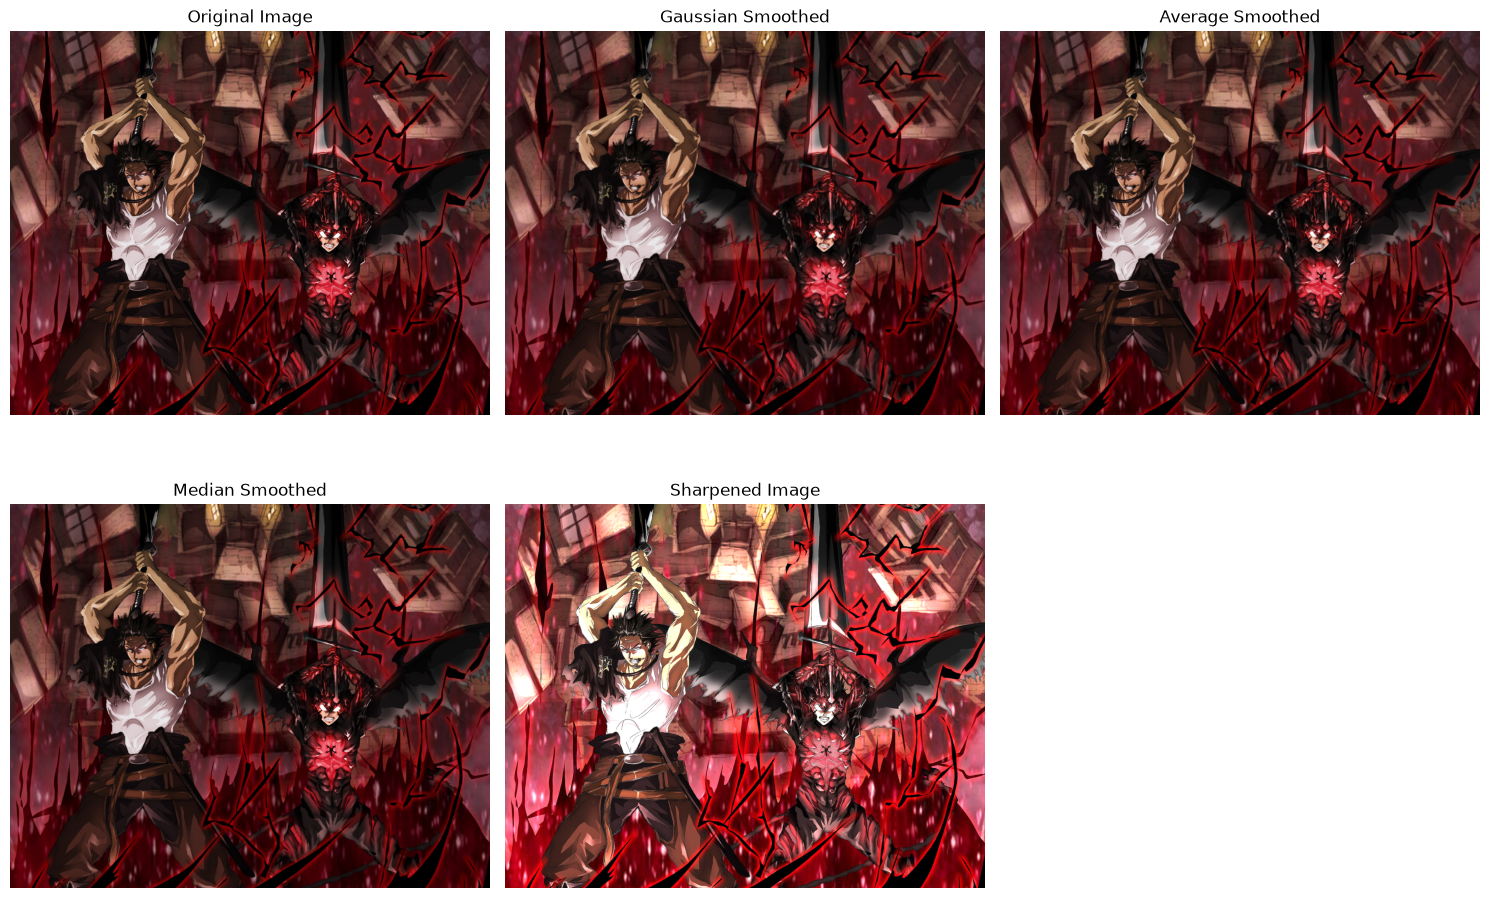

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = r"C:\Users\DileeP Kumar\OneDrive\Pictures\1241606.jpg"

image = cv2.imread(image_path)

if image is None:
    print("Error: Could not load image. Check the file path.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    kernel_size_gaussian = (7, 7)
    sigma = 2.0
    gaussian_kernel = cv2.getGaussianKernel(kernel_size_gaussian[0], sigma)
    gaussian_kernel = np.outer(gaussian_kernel, gaussian_kernel)
    smoothed_gaussian = cv2.filter2D(image_rgb, -1, gaussian_kernel)

    kernel_size_avg = (5, 5)
    averaging_kernel = np.ones(kernel_size_avg, dtype=np.float32) / (kernel_size_avg[0] * kernel_size_avg[1])
    smoothed_average = cv2.filter2D(image_rgb, -1, averaging_kernel)

    smoothed_median = cv2.medianBlur(image_rgb, 5)

    sharpening_kernel = np.array([[-1, -1, -1],
                                  [-1, 10, -1],
                                  [-1, -1, -1]])
    sharpened_image = cv2.filter2D(image_rgb, -1, sharpening_kernel)

    plt.figure(figsize=(15, 10))

    plt.subplot(2, 3, 1)
    plt.imshow(image_rgb)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(smoothed_gaussian)
    plt.title('Gaussian Smoothed')
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(smoothed_average)
    plt.title('Average Smoothed')
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.imshow(smoothed_median)
    plt.title('Median Smoothed')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(sharpened_image)
    plt.title('Sharpened Image')
    plt.axis('off')

    plt.tight_layout()
    plt.show()